# Eta10 Activity Model With Raw Electronic Descriptors

This notebook builds a separate machine-learning model for the HER activity target `eta10_mV`, defined as the overpotential required to reach `-10 mA/cm2` from LSV curves.

The goal is to keep this analysis separate from the H/D separation model:

- The target is `eta10_mV`, not `separation_coefficient`.
- `I_raw` is excluded from candidate descriptors to avoid using another LSV-derived activity proxy as a shortcut.
- Work function, PZC, and standard-potential descriptors are converted back to raw, unshifted elemental descriptors for mechanistic interpretation of `eta10`.
- Only true LSV crossings are used, and samples with `eta10 < 20 mV` are excluded because those values are comparable to the high-throughput LSV/RHE-conversion uncertainty scale.

Run `01_feature_selection_561_rs_from_eis_no_eis_fitting.ipynb` first if the 561-sample feature matrix is missing.

In [1]:

from pathlib import Path
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except Exception:
    HAS_XGB = False

warnings.filterwarnings("ignore", category=FutureWarning)

plt.rcParams["font.sans-serif"] = ["Arial"]
plt.rcParams["font.family"] = "Arial"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["text.color"] = "black"
plt.rcParams["axes.labelcolor"] = "black"
plt.rcParams["xtick.color"] = "black"
plt.rcParams["ytick.color"] = "black"

RANDOM_SEED = 17
SHE_OFFSET_V = 0.098
PH14_OFFSET_V = 0.0592 * 14
ETA10_MIN_MV = 20.0
ETA10_LABEL = r"$\eta_{10}$"
ETA10 = ETA10_LABEL

NOTEBOOK_DIR = Path.cwd()
if NOTEBOOK_DIR.name == "notebooks":
    ML_ROOT = NOTEBOOK_DIR.parent
else:
    ML_ROOT = NOTEBOOK_DIR / "hd_separation_ml"

REPO_ROOT = ML_ROOT.parent
ALL_DATA = ML_ROOT / "data_extraction" / "all_data"
LSV_DIR = ALL_DATA / "LSV"
LSV_GEOMETRY_METADATA = LSV_DIR / "lsv_geometry_area_metadata.csv"

SOURCE_FEATURE_DIR = ML_ROOT / "outputs" / "feature_selection_561_rs_from_eis_no_eis_fitting"
FEATURE_MATRIX_PATH = SOURCE_FEATURE_DIR / "feature_matrix_561_no_eis_fitting.csv"
CANDIDATE_FEATURES_PATH = SOURCE_FEATURE_DIR / "candidate_features.csv"

OUTPUT_DIR = ML_ROOT / "outputs" / "03_eta10_activity_model_raw_descriptors"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def format_axis_black_bold(ax, labelsize=13, linewidth=1.0):
    ax.tick_params(axis="both", which="both", labelsize=labelsize, colors="black", labelcolor="black")
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontname("Arial")
        label.set_fontweight("bold")
        label.set_color("black")
    ax.xaxis.label.set_fontname("Arial")
    ax.yaxis.label.set_fontname("Arial")
    ax.xaxis.label.set_fontweight("bold")
    ax.yaxis.label.set_fontweight("bold")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_fontname("Arial")
    ax.title.set_fontweight("bold")
    ax.title.set_color("black")
    for spine in ax.spines.values():
        spine.set_linewidth(linewidth)
        spine.set_color("black")


def format_legend_black(legend):
    if legend is None:
        return
    for text in legend.get_texts():
        text.set_fontname("Arial")
        text.set_fontweight("bold")
        text.set_color("black")
    legend.get_frame().set_edgecolor("black")
    legend.get_frame().set_linewidth(1.0)


def format_colorbar_black(cb, labelsize=12):
    cb.ax.tick_params(labelsize=labelsize, colors="black", labelcolor="black")
    for label in cb.ax.get_yticklabels():
        label.set_fontname("Arial")
        label.set_fontweight("bold")
        label.set_color("black")
    cb.ax.yaxis.label.set_fontname("Arial")
    cb.ax.yaxis.label.set_fontweight("bold")
    cb.ax.yaxis.label.set_color("black")
    cb.outline.set_edgecolor("black")
    cb.outline.set_linewidth(1.0)


def save_png_pdf(fig, stem, dpi=600):
    png_path = OUTPUT_DIR / f"{stem}.png"
    pdf_path = OUTPUT_DIR / f"{stem}.pdf"
    fig.savefig(png_path, dpi=dpi, bbox_inches="tight", pad_inches=0.08)
    fig.savefig(pdf_path, bbox_inches="tight", pad_inches=0.08)
    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")


def display_feature_name(feature):
    mapping = {
        "Rs_from_EIS": "Rs from EIS",
        "work_function_element1": "Work Function of Metal 1",
        "work_function_element2": "Work Function of Metal 2",
        "pzc_element1": "PZC of Metal 1",
        "pzc_element2": "PZC of Metal 2",
        "E_std_element1": "Standard Potential of Metal 1",
        "E_std_element2": "Standard Potential of Metal 2",
        "FE_ads_avg_element1": "H Adsorption Energy of Metal 1",
        "FE_ads_avg_element2": "H Adsorption Energy of Metal 2",
        "delta_EOH_element1": "OH Adsorption Energy of Metal 1",
        "delta_EOH_element2": "OH Adsorption Energy of Metal 2",
        "electronegativity_element1": "Electronegativity of Metal 1",
        "electronegativity_element2": "Electronegativity of Metal 2",
        "MH_bond_kJ_element1": "M-H Bond Energy of Metal 1",
        "MH_bond_kJ_element2": "M-H Bond Energy of Metal 2",
        "MD_bond_kJ_element1": "M-D Bond Energy of Metal 1",
        "MD_bond_kJ_element2": "M-D Bond Energy of Metal 2",
        "Frequency_OH_element1": "OH Frequency of Metal 1",
        "Frequency_OH_element2": "OH Frequency of Metal 2",
        "Frequency_H_element1": "H Frequency of Metal 1",
        "Frequency_H_element2": "H Frequency of Metal 2",
        "Frequency_D_element1": "D Frequency of Metal 1",
        "Frequency_D_element2": "D Frequency of Metal 2",
        "delta_ZPE_H_element1": "H/D ZPE Difference of Metal 1",
        "delta_ZPE_H_element2": "H/D ZPE Difference of Metal 2",
    }
    return mapping.get(feature, feature)


print(f"ML root: {ML_ROOT}")
print(f"Output directory: {OUTPUT_DIR}")
print(f"XGBoost available: {HAS_XGB}")


ML root: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml
Output directory: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors
XGBoost available: True


In [2]:
def read_lsv_curve(path: Path) -> pd.DataFrame:
    """Read the plain-text LSV export used in all_data/LSV."""
    rows = []
    header_seen = False
    with open(path, "r", encoding="utf-8", errors="ignore") as handle:
        for line in handle:
            text = line.strip()
            if not text:
                continue
            lower = text.lower()
            if ("potential" in lower or lower.startswith("e(v)")) and ("current" in lower or "i(a" in lower):
                header_seen = True
                continue
            if not header_seen:
                continue
            parts = text.split("\t")
            if len(parts) < 2:
                continue
            try:
                rows.append((float(parts[0]), float(parts[1])))
            except ValueError:
                continue
    if not rows:
        raise ValueError(f"No numeric LSV data found in {path}")
    return pd.DataFrame(rows, columns=["E_raw_V", "current_A_or_A_per_cm2"])


def load_lsv_geometry_area_map() -> dict:
    """Return per-sample LSV geometry areas. Unlisted samples use 1 cm2."""
    if not LSV_GEOMETRY_METADATA.exists():
        return {}
    meta = pd.read_csv(LSV_GEOMETRY_METADATA)
    return dict(zip(meta["catalyst"].astype(str), pd.to_numeric(meta["geometry_area_cm2"], errors="coerce")))


def extract_eta10_from_lsv(sample: str, geometry_area_map: dict) -> dict:
    """Extract eta10 from LSV.

    For samples measured with a 2 cm2 geometry, the comparable eta10 is extracted
    at raw -20 mA according to data_extraction/all_data/LSV/README.md.
    If multiple crossings occur, the most negative potential is used as a
    conservative/worst eta10 estimate.
    """
    path = LSV_DIR / f"{sample}.txt"
    if not path.exists():
        return {"sample": sample, "lsv_found": False}

    lsv = read_lsv_curve(path)
    area_cm2 = float(geometry_area_map.get(sample, 1.0))
    target_current = -0.01 * area_cm2

    e = lsv["E_raw_V"].to_numpy(dtype=float)
    current = lsv["current_A_or_A_per_cm2"].to_numpy(dtype=float)
    delta = current - target_current

    crossings = []
    for idx in range(len(current) - 1):
        d0, d1 = delta[idx], delta[idx + 1]
        if np.isnan(d0) or np.isnan(d1):
            continue
        if d0 == 0:
            crossings.append(e[idx])
        if d0 * d1 < 0 or d1 == 0:
            if current[idx + 1] != current[idx]:
                frac = (target_current - current[idx]) / (current[idx + 1] - current[idx])
                if 0 <= frac <= 1:
                    crossings.append(e[idx] + frac * (e[idx + 1] - e[idx]))
            else:
                crossings.append(e[idx + 1])

    nearest_idx = int(np.argmin(np.abs(current - target_current)))
    if crossings:
        e_target = float(np.min(crossings))
        crossed = True
        n_crossings = len(crossings)
    else:
        e_target = float(e[nearest_idx])
        crossed = False
        n_crossings = 0

    potential_vs_rhe_v = e_target + PH14_OFFSET_V + SHE_OFFSET_V
    eta10_mV = -1000 * potential_vs_rhe_v

    return {
        "sample": sample,
        "lsv_found": True,
        "geometry_area_cm2": area_cm2,
        "target_current_raw_A_or_A_per_cm2": target_current,
        "eta10_crossed": crossed,
        "n_crossings": n_crossings,
        "E_raw_at_target_or_nearest_V": e_target,
        "Potential_vs_RHE_at_target_or_nearest_mV": 1000 * potential_vs_rhe_v,
        "eta10_mV": eta10_mV,
        "min_current_A_or_A_per_cm2": float(np.nanmin(current)),
        "max_current_A_or_A_per_cm2": float(np.nanmax(current)),
        "nearest_current_A_or_A_per_cm2": float(current[nearest_idx]),
    }


def rmse(y_true, y_pred) -> float:
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

In [3]:
feature_matrix = pd.read_csv(FEATURE_MATRIX_PATH)
candidate_features = pd.read_csv(CANDIDATE_FEATURES_PATH).iloc[:, 0].tolist()

geometry_area_map = load_lsv_geometry_area_map()
eta_records = [extract_eta10_from_lsv(sample, geometry_area_map) for sample in feature_matrix["sample"].astype(str)]
eta10_table = pd.DataFrame(eta_records)
eta10_table.to_csv(OUTPUT_DIR / "eta10_extracted_from_lsv_561.csv", index=False)

print(eta10_table[["lsv_found", "eta10_crossed"]].value_counts(dropna=False).to_string())
print(eta10_table["eta10_mV"].describe().to_string())

lsv_found  eta10_crossed
True       True             323
           False            238
count    561.000000
mean     401.020510
std      185.800088
min       -6.773876
25%      239.897885
50%      485.780729
75%      571.240557
max      705.359886


In [4]:
merged = feature_matrix.merge(
    eta10_table[["sample", "eta10_mV", "eta10_crossed", "n_crossings", "geometry_area_cm2"]],
    on="sample",
    how="left",
)

# Convert the potential-referenced electronic descriptors back to raw elemental descriptors.
# Original pipeline: offset = E_IR_corrected_final + SHE_OFFSET_V
# shifted work_function = raw work_function + offset
# shifted pzc/E_std = raw pzc/E_std - offset
raw_matrix = merged.copy()
offset = pd.to_numeric(raw_matrix["E_IR_corrected_final"], errors="coerce") + SHE_OFFSET_V
for col in ["work_function_element1", "work_function_element2"]:
    raw_matrix[col] = pd.to_numeric(raw_matrix[col], errors="coerce") - offset
for col in ["pzc_element1", "pzc_element2", "E_std_element1", "E_std_element2"]:
    raw_matrix[col] = pd.to_numeric(raw_matrix[col], errors="coerce") + offset

true_crossing = raw_matrix[(raw_matrix["eta10_crossed"] == True) & raw_matrix["eta10_mV"].notna()].copy()
excluded_low_eta = true_crossing[true_crossing["eta10_mV"] < ETA10_MIN_MV].copy()
model_data = true_crossing[true_crossing["eta10_mV"] >= ETA10_MIN_MV].copy()

raw_matrix.to_csv(OUTPUT_DIR / "feature_matrix_561_with_eta10_raw_electronic_descriptors.csv", index=False)
model_data.to_csv(OUTPUT_DIR / "eta10_ge20_model_dataset_raw_descriptors.csv", index=False)
excluded_low_eta[["sample", "eta10_mV", "n_crossings", "geometry_area_cm2"]].sort_values("eta10_mV").to_csv(
    OUTPUT_DIR / "excluded_eta10_lt_20mV.csv", index=False
)

print(f"True eta10 crossings: {len(true_crossing)}")
print(f"Excluded eta10 < {ETA10_MIN_MV:.0f} mV: {len(excluded_low_eta)}")
print(f"Model dataset: {len(model_data)}")
print(excluded_low_eta[["sample", "eta10_mV"]].sort_values("eta10_mV").to_string(index=False))

True eta10 crossings: 323
Excluded eta10 < 20 mV: 4
Model dataset: 319
sample  eta10_mV
  Cd-Y -6.047312
  W-Pb -5.964056
 Ce-Pb  6.860709
 Sc-Pb 12.374395


In [5]:
candidate_features_no_iraw = [
    feature for feature in candidate_features
    if feature != "I_raw" and feature in model_data.columns
]

work = model_data[["sample", "eta10_mV"] + candidate_features_no_iraw].copy()
for col in ["eta10_mV"] + candidate_features_no_iraw:
    work[col] = pd.to_numeric(work[col], errors="coerce")
work = work.dropna(subset=["eta10_mV"]).reset_index(drop=True)

X = work[candidate_features_no_iraw]
y = work["eta10_mV"].to_numpy(dtype=float)

try:
    stratify_bins = pd.qcut(y, q=8, labels=False, duplicates="drop")
    if len(pd.Series(stratify_bins).dropna().unique()) < 2:
        stratify_bins = None
except Exception:
    stratify_bins = None

X_train, X_test, y_train, y_test, sample_train, sample_test = train_test_split(
    X,
    y,
    work["sample"].to_numpy(),
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=stratify_bins,
)

print(f"Candidate features without I_raw: {len(candidate_features_no_iraw)}")
print(f"Train/test: {len(X_train)}/{len(X_test)}")

Candidate features without I_raw: 27
Train/test: 255/64


In [6]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
selection_model = ExtraTreesRegressor(
    n_estimators=150,
    min_samples_split=5,
    min_samples_leaf=1,
    max_depth=None,
    random_state=RANDOM_SEED,
    n_jobs=-1,
)


def score_subset(features):
    pipeline = make_pipeline(SimpleImputer(strategy="median"), selection_model)
    scores = cross_val_score(pipeline, X_train[features], y_train, cv=cv, scoring="r2")
    return float(scores.mean()), float(scores.std())

start_time = time.time()
current_features = list(candidate_features_no_iraw)
history = []
all_removal_scores = []
removed_to_get_here = ""
step = 0

while len(current_features) >= 1:
    mean_score, std_score = score_subset(current_features)
    history.append({
        "step": step,
        "n_features": len(current_features),
        "cv_r2_mean": mean_score,
        "cv_r2_std": std_score,
        "removed_to_get_here": removed_to_get_here,
        "features": ";".join(current_features),
    })
    if len(current_features) == 1:
        break

    removal_rows = []
    for feature in current_features:
        subset = [col for col in current_features if col != feature]
        subset_mean, subset_std = score_subset(subset)
        removal_rows.append({
            "step": step + 1,
            "remove_feature": feature,
            "remaining_n_features": len(subset),
            "cv_r2_mean": subset_mean,
            "cv_r2_std": subset_std,
        })
    removal_df = pd.DataFrame(removal_rows).sort_values("cv_r2_mean", ascending=False)
    removal_df.to_csv(OUTPUT_DIR / f"elimination_step_{step + 1:02d}_removal_scores.csv", index=False)
    all_removal_scores.extend(removal_rows)

    removed_to_get_here = str(removal_df.iloc[0]["remove_feature"])
    current_features = [col for col in current_features if col != removed_to_get_here]
    step += 1

history_df = pd.DataFrame(history)
history_df.to_csv(OUTPUT_DIR / "backward_elimination_history_eta10_raw_descriptors.csv", index=False)
pd.DataFrame(all_removal_scores).to_csv(OUTPUT_DIR / "all_removal_scores_eta10_raw_descriptors.csv", index=False)

best_row = history_df.sort_values("cv_r2_mean", ascending=False).iloc[0]
selected_features = best_row["features"].split(";")
pd.DataFrame({"selected_feature": selected_features}).to_csv(OUTPUT_DIR / "selected_features_eta10_raw_descriptors.csv", index=False)

print(f"Feature selection runtime: {time.time() - start_time:.1f} s")
print(f"Best feature count: {len(selected_features)}")
print(f"Best selection CV R2: {best_row['cv_r2_mean']:.4f}")
print(selected_features)

Feature selection runtime: 296.0 s
Best feature count: 9
Best selection CV R2: 0.7689
['Rs_from_EIS', 'work_function_element1', 'work_function_element2', 'pzc_element2', 'E_std_element2', 'FE_ads_avg_element2', 'delta_EOH_element1', 'MH_bond_kJ_element2', 'delta_ZPE_H_element1']


In [7]:
models = [
    (
        "Extra Trees",
        ExtraTreesRegressor(
            n_estimators=500,
            min_samples_split=5,
            min_samples_leaf=1,
            max_depth=None,
            random_state=RANDOM_SEED,
            n_jobs=-1,
        ),
    ),
    (
        "Random Forest",
        RandomForestRegressor(
            n_estimators=500,
            min_samples_split=2,
            min_samples_leaf=1,
            max_depth=None,
            random_state=RANDOM_SEED,
            n_jobs=-1,
        ),
    ),
]

if HAS_XGB:
    models.append(
        (
            "XGBoost",
            XGBRegressor(
                n_estimators=200,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.8,
                objective="reg:squarederror",
                random_state=RANDOM_SEED,
                n_jobs=-1,
            ),
        )
    )

result_rows = []
best_pipeline = None
best_prediction = None
best_model_name = None
best_test_r2 = -np.inf

for model_name, model in models:
    pipeline = make_pipeline(SimpleImputer(strategy="median"), model)
    cv_scores = cross_val_score(pipeline, X_train[selected_features], y_train, cv=cv, scoring="r2")
    pipeline.fit(X_train[selected_features], y_train)
    pred_train = pipeline.predict(X_train[selected_features])
    pred_test = pipeline.predict(X_test[selected_features])
    row = {
        "model_name": model_name,
        "n_features": len(selected_features),
        "cv_r2_mean": float(cv_scores.mean()),
        "cv_r2_std": float(cv_scores.std()),
        "train_r2": float(r2_score(y_train, pred_train)),
        "test_r2": float(r2_score(y_test, pred_test)),
        "train_rmse_mV": rmse(y_train, pred_train),
        "test_rmse_mV": rmse(y_test, pred_test),
    }
    result_rows.append(row)
    if row["test_r2"] > best_test_r2:
        best_test_r2 = row["test_r2"]
        best_pipeline = pipeline
        best_prediction = pred_test
        best_model_name = model_name

results_df = pd.DataFrame(result_rows).sort_values("test_r2", ascending=False)
results_df.to_csv(OUTPUT_DIR / "eta10_raw_descriptor_model_results.csv", index=False)
print(results_df.to_string(index=False))

   model_name  n_features  cv_r2_mean  cv_r2_std  train_r2  test_r2  train_rmse_mV  test_rmse_mV
  Extra Trees           9    0.766499   0.044035  0.973594 0.672275      26.119754     92.862512
      XGBoost           9    0.707682   0.081222  0.925098 0.650403      43.991435     95.911151
Random Forest           9    0.731532   0.078522  0.963986 0.633527      30.503807     98.198843


In [8]:
native_importance = (
    best_pipeline[-1].feature_importances_
    if hasattr(best_pipeline[-1], "feature_importances_")
    else np.full(len(selected_features), np.nan)
)

permutation = permutation_importance(
    best_pipeline,
    X_test[selected_features],
    y_test,
    n_repeats=20,
    random_state=RANDOM_SEED,
    scoring="r2",
    n_jobs=-1,
)

importance_df = pd.DataFrame({
    "feature": selected_features,
    "native_importance": native_importance,
    "permutation_importance_mean": permutation.importances_mean,
    "permutation_importance_std": permutation.importances_std,
}).sort_values("native_importance", ascending=False)
importance_df.to_csv(OUTPUT_DIR / "eta10_raw_descriptor_feature_importance.csv", index=False)

prediction_df = pd.DataFrame({
    "sample": sample_test,
    "true_eta10_mV": y_test,
    "predicted_eta10_mV": best_prediction,
    "residual_pred_minus_true_mV": best_prediction - y_test,
}).sort_values("true_eta10_mV")
prediction_df.to_csv(OUTPUT_DIR / "eta10_raw_descriptor_test_predictions.csv", index=False)

summary = {
    "target": "eta10_mV",
    "eta10_definition": "LSV overpotential at -10 mA/cm2; 2 cm2 exceptions use raw -20 mA",
    "excluded_low_eta_threshold_mV": ETA10_MIN_MV,
    "n_true_crossings_before_filter": int(len(true_crossing)),
    "n_excluded_eta10_lt_20mV": int(len(excluded_low_eta)),
    "n_model_samples": int(len(work)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
    "candidate_features": candidate_features_no_iraw,
    "selected_features": selected_features,
    "best_model": best_model_name,
    "best_test_r2": float(best_test_r2),
    "best_test_rmse_mV": float(results_df.iloc[0]["test_rmse_mV"]),
    "output_dir": str(OUTPUT_DIR),
}
(OUTPUT_DIR / "summary_eta10_raw_descriptor_model.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

print(json.dumps(summary, indent=2))
print(importance_df.to_string(index=False))

{
  "target": "eta10_mV",
  "eta10_definition": "LSV overpotential at -10 mA/cm2; 2 cm2 exceptions use raw -20 mA",
  "excluded_low_eta_threshold_mV": 20.0,
  "n_true_crossings_before_filter": 323,
  "n_excluded_eta10_lt_20mV": 4,
  "n_model_samples": 319,
  "n_train": 255,
  "n_test": 64,
  "candidate_features": [
    "Rs_from_EIS",
    "work_function_element1",
    "work_function_element2",
    "pzc_element1",
    "pzc_element2",
    "MM_bond_element1",
    "MM_bond_element2",
    "E_std_element1",
    "E_std_element2",
    "FE_ads_avg_element1",
    "FE_ads_avg_element2",
    "delta_EOH_element1",
    "delta_EOH_element2",
    "electronegativity_element1",
    "electronegativity_element2",
    "MH_bond_kJ_element1",
    "MH_bond_kJ_element2",
    "MD_bond_kJ_element1",
    "MD_bond_kJ_element2",
    "Frequency_OH_element1",
    "Frequency_OH_element2",
    "Frequency_H_element1",
    "Frequency_H_element2",
    "Frequency_D_element1",
    "Frequency_D_element2",
    "delta_ZPE_H_ele

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_backward_elimination.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_backward_elimination.pdf


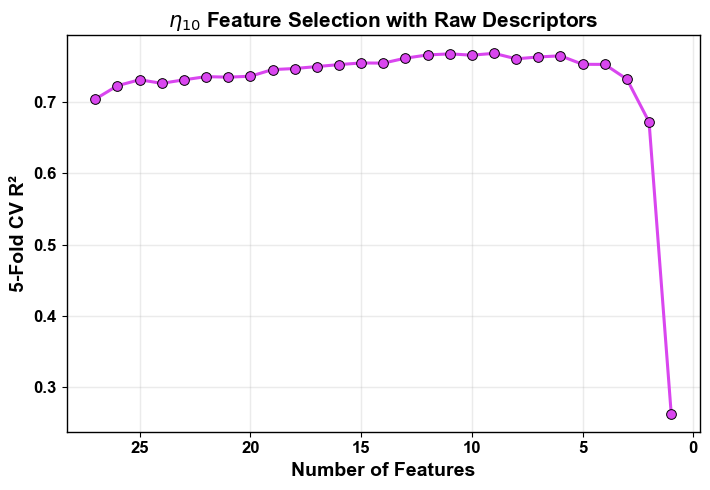

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_prediction_residual.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_prediction_residual.pdf


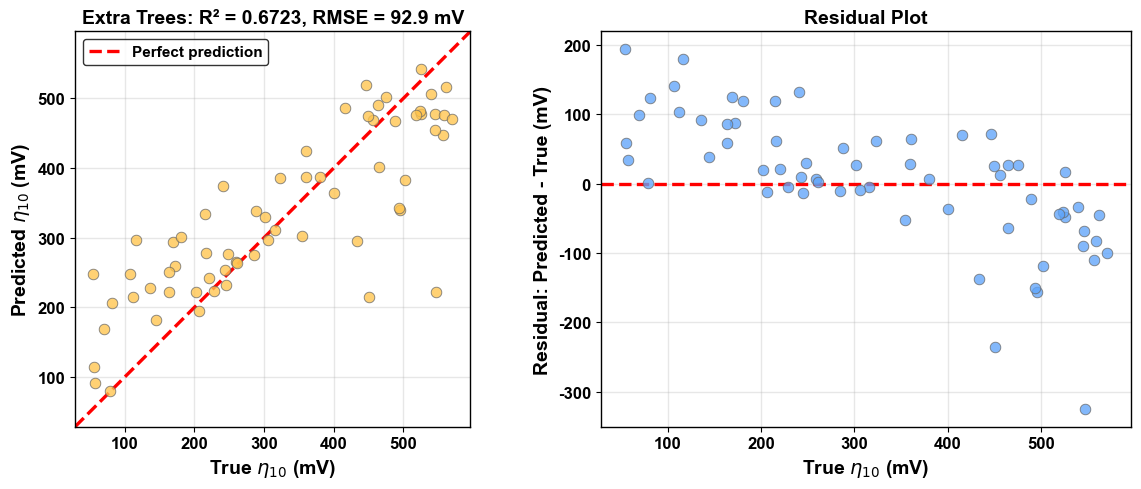

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_test_prediction_publication_style.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_test_prediction_publication_style.pdf


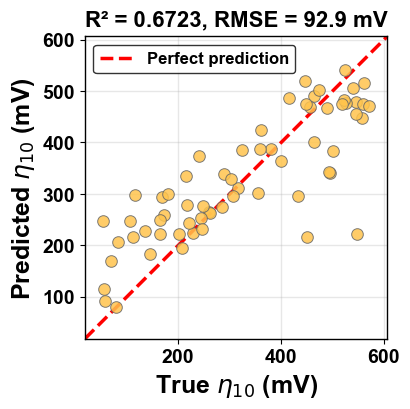

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_feature_importance.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_feature_importance.pdf


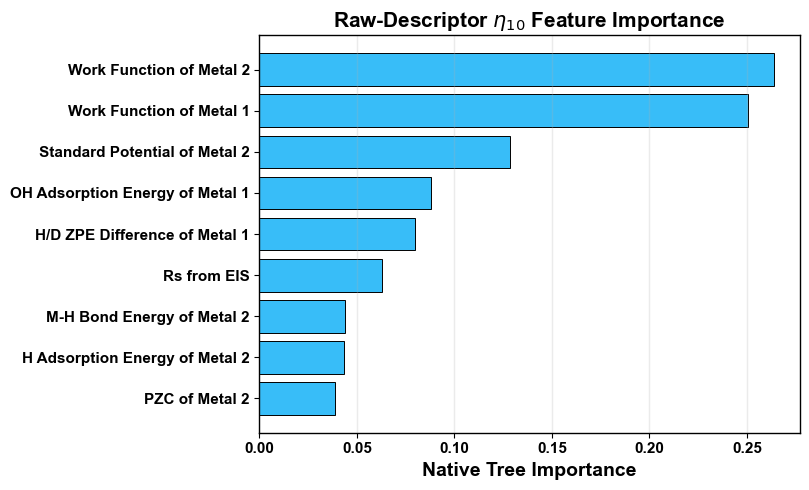

In [9]:

# Feature-selection trace
fig, ax = plt.subplots(figsize=(7.2, 5.0))
ax.plot(
    history_df["n_features"],
    history_df["cv_r2_mean"],
    marker="o",
    markersize=7,
    linewidth=2.2,
    color="#d946ef",
    markeredgecolor="black",
    markeredgewidth=0.7,
)
ax.invert_xaxis()
ax.set_xlabel("Number of Features", fontsize=14, fontweight="bold", color="black")
ax.set_ylabel("5-Fold CV R²", fontsize=14, fontweight="bold", color="black")
ax.set_title(f"{ETA10} Feature Selection with Raw Descriptors", fontsize=15, fontweight="bold", color="black")
ax.grid(alpha=0.25, linewidth=1.0)
format_axis_black_bold(ax, labelsize=12)
fig.tight_layout()
save_png_pdf(fig, "eta10_raw_descriptor_backward_elimination")
plt.show()
plt.close(fig)

# Prediction and residual plot
fig, axes = plt.subplots(1, 2, figsize=(12.0, 5.0))
lo = min(np.min(y_test), np.min(best_prediction))
hi = max(np.max(y_test), np.max(best_prediction))
pad = 0.05 * (hi - lo)
lo -= pad
hi += pad

axes[0].scatter(
    y_test,
    best_prediction,
    s=58,
    alpha=0.78,
    color="#ffc44d",
    edgecolor="#666666",
    linewidth=0.65,
    zorder=3,
)
axes[0].plot([lo, hi], [lo, hi], color="red", linestyle="--", lw=2.4, label="Perfect prediction", zorder=2)
axes[0].set_xlim(lo, hi)
axes[0].set_ylim(lo, hi)
axes[0].set_aspect("equal", adjustable="box")
axes[0].set_xlabel(f"True {ETA10} (mV)", fontsize=14, fontweight="bold", color="black")
axes[0].set_ylabel(f"Predicted {ETA10} (mV)", fontsize=14, fontweight="bold", color="black")
axes[0].set_title(
    f"{best_model_name}: R² = {best_test_r2:.4f}, RMSE = {results_df.iloc[0]['test_rmse_mV']:.1f} mV",
    fontsize=14,
    fontweight="bold",
    color="black",
)
legend = axes[0].legend(frameon=True, fontsize=11, loc="upper left")
format_legend_black(legend)
axes[0].grid(alpha=0.30, linewidth=1.0)
format_axis_black_bold(axes[0], labelsize=12)

residual = best_prediction - y_test
axes[1].scatter(
    y_test,
    residual,
    s=58,
    alpha=0.78,
    color="#60a5fa",
    edgecolor="#666666",
    linewidth=0.65,
    zorder=3,
)
axes[1].axhline(0, color="red", linestyle="--", lw=2.4)
axes[1].set_xlabel(f"True {ETA10} (mV)", fontsize=14, fontweight="bold", color="black")
axes[1].set_ylabel("Residual: Predicted - True (mV)", fontsize=14, fontweight="bold", color="black")
axes[1].set_title("Residual Plot", fontsize=14, fontweight="bold", color="black")
axes[1].grid(alpha=0.30, linewidth=1.0)
format_axis_black_bold(axes[1], labelsize=12)
fig.tight_layout()
save_png_pdf(fig, "eta10_raw_descriptor_prediction_residual")
plt.show()
plt.close(fig)

# Publication-style test prediction plot, matched to notebook 02 style.
y_true = np.asarray(y_test)
y_pred = np.asarray(best_prediction)
r2 = r2_score(y_true, y_pred)
rmse_value = np.sqrt(mean_squared_error(y_true, y_pred))

fig, ax = plt.subplots(figsize=(4.2, 5.0))
ax.scatter(
    y_true,
    y_pred,
    s=70,
    color="#ffc44d",
    edgecolors="#666666",
    linewidths=0.7,
    alpha=0.85,
    zorder=3,
)
min_val = min(y_true.min(), y_pred.min())
max_val = max(y_true.max(), y_pred.max())
pad = 0.07 * (max_val - min_val)
plot_min = min_val - pad
plot_max = max_val + pad
ax.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    color="red",
    linestyle="--",
    linewidth=2.5,
    label="Perfect prediction",
    zorder=2,
)
ax.set_xlim(plot_min, plot_max)
ax.set_ylim(plot_min, plot_max)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel(f"True {ETA10} (mV)", fontsize=18, fontweight="bold", color="black")
ax.set_ylabel(f"Predicted {ETA10} (mV)", fontsize=18, fontweight="bold", color="black")
ax.set_title(f"R² = {r2:.4f}, RMSE = {rmse_value:.1f} mV", fontsize=16, fontweight="bold", color="black", pad=8)
ax.grid(True, alpha=0.3, linewidth=1.0)
legend = ax.legend(loc="upper left", frameon=True, fontsize=12)
format_legend_black(legend)
format_axis_black_bold(ax, labelsize=14)
fig.tight_layout()
save_png_pdf(fig, "eta10_test_prediction_publication_style")
plt.show()
plt.close(fig)

# Feature importance
fig, ax = plt.subplots(figsize=(8.2, 5.0))
plot_importance = importance_df.sort_values("native_importance").copy()
plot_importance["display_feature"] = plot_importance["feature"].map(display_feature_name)
ax.barh(
    plot_importance["display_feature"],
    plot_importance["native_importance"],
    color="#38bdf8",
    edgecolor="black",
    linewidth=0.7,
)
ax.set_xlabel("Native Tree Importance", fontsize=14, fontweight="bold", color="black")
ax.set_title(f"Raw-Descriptor {ETA10} Feature Importance", fontsize=15, fontweight="bold", color="black")
ax.grid(axis="x", alpha=0.25, linewidth=1.0)
format_axis_black_bold(ax, labelsize=11)
fig.tight_layout()
save_png_pdf(fig, "eta10_raw_descriptor_feature_importance")
plt.show()
plt.close(fig)


{'corr_raw_work_function_element1_eta10': np.float64(-0.269937852133054), 'corr_raw_work_function_element2_eta10': np.float64(-0.357027342401134)}


Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_workfunction1_workfunction2_distribution.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_workfunction1_workfunction2_distribution.pdf


Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\raw_workfunction1_vs_workfunction2_eta10_projection.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\raw_workfunction1_vs_workfunction2_eta10_projection.pdf


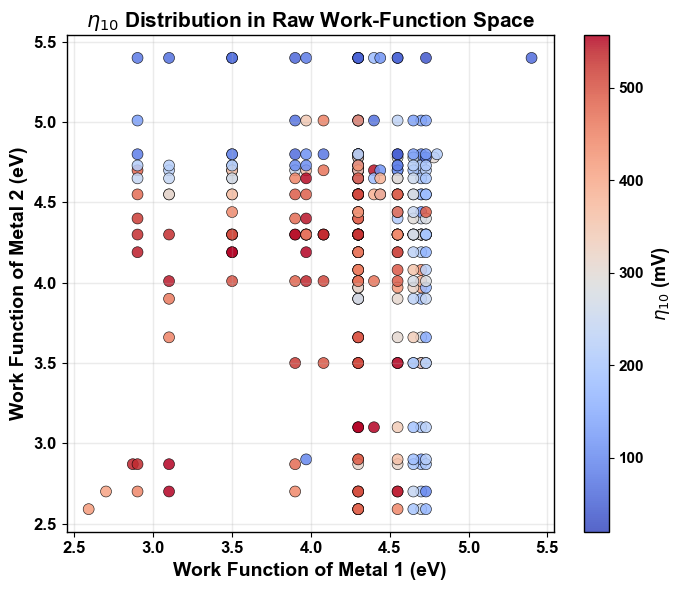

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\raw_workfunction_binned_median_eta10_landscape.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\raw_workfunction_binned_median_eta10_landscape.pdf


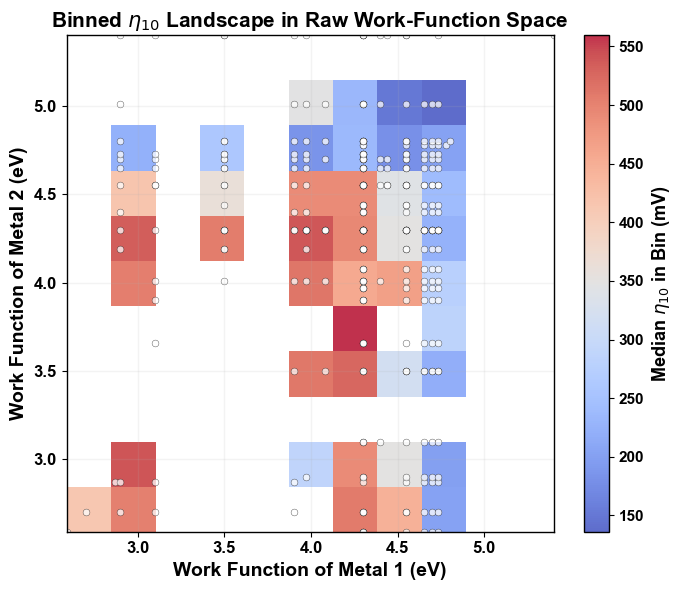

Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_vs_raw_workfunction_elements.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_vs_raw_workfunction_elements.pdf


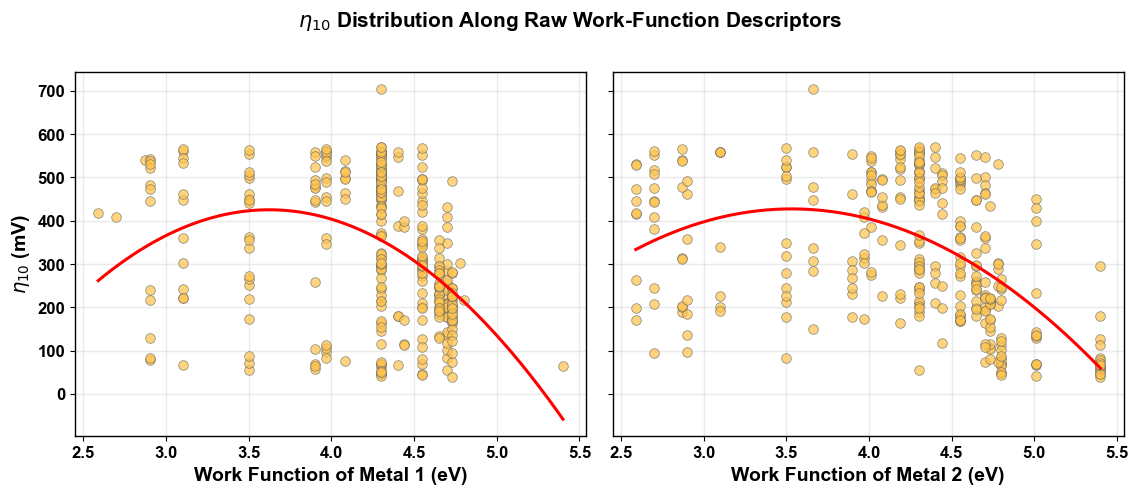

In [10]:

# Raw work-function projections and eta10 distribution in work-function space.
plot_data = work.copy()
plot_data["work_function_element1"] = pd.to_numeric(plot_data["work_function_element1"], errors="coerce")
plot_data["work_function_element2"] = pd.to_numeric(plot_data["work_function_element2"], errors="coerce")
plot_data["eta10_mV"] = pd.to_numeric(plot_data["eta10_mV"], errors="coerce")
plot_data = plot_data.dropna(subset=["work_function_element1", "work_function_element2", "eta10_mV"]).copy()

wf_stats = {
    "corr_raw_work_function_element1_eta10": plot_data[["work_function_element1", "eta10_mV"]].corr().iloc[0, 1],
    "corr_raw_work_function_element2_eta10": plot_data[["work_function_element2", "eta10_mV"]].corr().iloc[0, 1],
}
(OUTPUT_DIR / "raw_work_function_eta10_correlations.json").write_text(json.dumps(wf_stats, indent=2), encoding="utf-8")
print(wf_stats)

eta_vmax = np.nanpercentile(plot_data["eta10_mV"], 95)

fig, ax = plt.subplots(figsize=(7.0, 6.0))
sc = ax.scatter(
    plot_data["work_function_element1"],
    plot_data["work_function_element2"],
    c=plot_data["eta10_mV"],
    cmap="coolwarm",
    vmin=ETA10_MIN_MV,
    vmax=eta_vmax,
    s=62,
    alpha=0.86,
    edgecolor="black",
    linewidth=0.45,
)
cb = fig.colorbar(sc, ax=ax)
cb.set_label(f"{ETA10} (mV)", fontsize=13, fontweight="bold", color="black")
format_colorbar_black(cb, labelsize=11)
ax.set_xlabel("Work Function of Metal 1 (eV)", fontsize=14, fontweight="bold", color="black")
ax.set_ylabel("Work Function of Metal 2 (eV)", fontsize=14, fontweight="bold", color="black")
ax.set_title(f"{ETA10} Distribution in Raw Work-Function Space", fontsize=15, fontweight="bold", color="black")
ax.grid(alpha=0.25, linewidth=1.0)
format_axis_black_bold(ax, labelsize=12)
fig.tight_layout()
save_png_pdf(fig, "eta10_workfunction1_workfunction2_distribution")
# Keep the earlier filename as an alias for downstream references.
save_png_pdf(fig, "raw_workfunction1_vs_workfunction2_eta10_projection")
plt.show()
plt.close(fig)

# Binned median landscape in work-function space.
x = plot_data["work_function_element1"].to_numpy(dtype=float)
y_wf = plot_data["work_function_element2"].to_numpy(dtype=float)
z = plot_data["eta10_mV"].to_numpy(dtype=float)
xbins = np.linspace(np.nanmin(x), np.nanmax(x), 12)
ybins = np.linspace(np.nanmin(y_wf), np.nanmax(y_wf), 12)
heat = np.full((len(ybins) - 1, len(xbins) - 1), np.nan)
for i in range(len(xbins) - 1):
    for j in range(len(ybins) - 1):
        mask = (x >= xbins[i]) & (x < xbins[i + 1]) & (y_wf >= ybins[j]) & (y_wf < ybins[j + 1])
        if mask.sum() >= 2:
            heat[j, i] = np.nanmedian(z[mask])

fig, ax = plt.subplots(figsize=(7.0, 6.0))
im = ax.imshow(
    heat,
    origin="lower",
    extent=[xbins[0], xbins[-1], ybins[0], ybins[-1]],
    aspect="auto",
    cmap="coolwarm",
    alpha=0.82,
)
ax.scatter(
    plot_data["work_function_element1"],
    plot_data["work_function_element2"],
    s=24,
    color="white",
    edgecolor="black",
    linewidth=0.3,
    alpha=0.74,
)
cb = fig.colorbar(im, ax=ax)
cb.set_label(f"Median {ETA10} in Bin (mV)", fontsize=13, fontweight="bold", color="black")
format_colorbar_black(cb, labelsize=11)
ax.set_xlabel("Work Function of Metal 1 (eV)", fontsize=14, fontweight="bold", color="black")
ax.set_ylabel("Work Function of Metal 2 (eV)", fontsize=14, fontweight="bold", color="black")
ax.set_title(f"Binned {ETA10} Landscape in Raw Work-Function Space", fontsize=15, fontweight="bold", color="black")
ax.grid(alpha=0.15, linewidth=1.0)
format_axis_black_bold(ax, labelsize=12)
fig.tight_layout()
save_png_pdf(fig, "raw_workfunction_binned_median_eta10_landscape")
plt.show()
plt.close(fig)

# One-dimensional eta10 distributions along each work-function descriptor.
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), sharey=True)
for ax, feature, label in [
    (axes[0], "work_function_element1", "Work Function of Metal 1 (eV)"),
    (axes[1], "work_function_element2", "Work Function of Metal 2 (eV)"),
]:
    sub = plot_data[[feature, "eta10_mV"]].dropna().copy()
    ax.scatter(
        sub[feature],
        sub["eta10_mV"],
        s=48,
        alpha=0.72,
        color="#ffc44d",
        edgecolor="#666666",
        linewidth=0.55,
        zorder=3,
    )
    if sub[feature].nunique() > 2:
        xs = np.linspace(sub[feature].min(), sub[feature].max(), 200)
        coeff = np.polyfit(sub[feature], sub["eta10_mV"], deg=2)
        ax.plot(xs, np.polyval(coeff, xs), color="red", lw=2.2, zorder=4)
    ax.set_xlabel(label, fontsize=14, fontweight="bold", color="black")
    ax.grid(alpha=0.25, linewidth=1.0)
    format_axis_black_bold(ax, labelsize=12)
axes[0].set_ylabel(f"{ETA10} (mV)", fontsize=14, fontweight="bold", color="black")
fig.suptitle(f"{ETA10} Distribution Along Raw Work-Function Descriptors", fontsize=15, fontweight="bold", color="black", y=1.02)
fig.tight_layout()
save_png_pdf(fig, "eta10_vs_raw_workfunction_elements")
plt.show()
plt.close(fig)


Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\raw_selected_features_vs_eta10_scatter_grid.png
Saved: C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\raw_selected_features_vs_eta10_scatter_grid.pdf


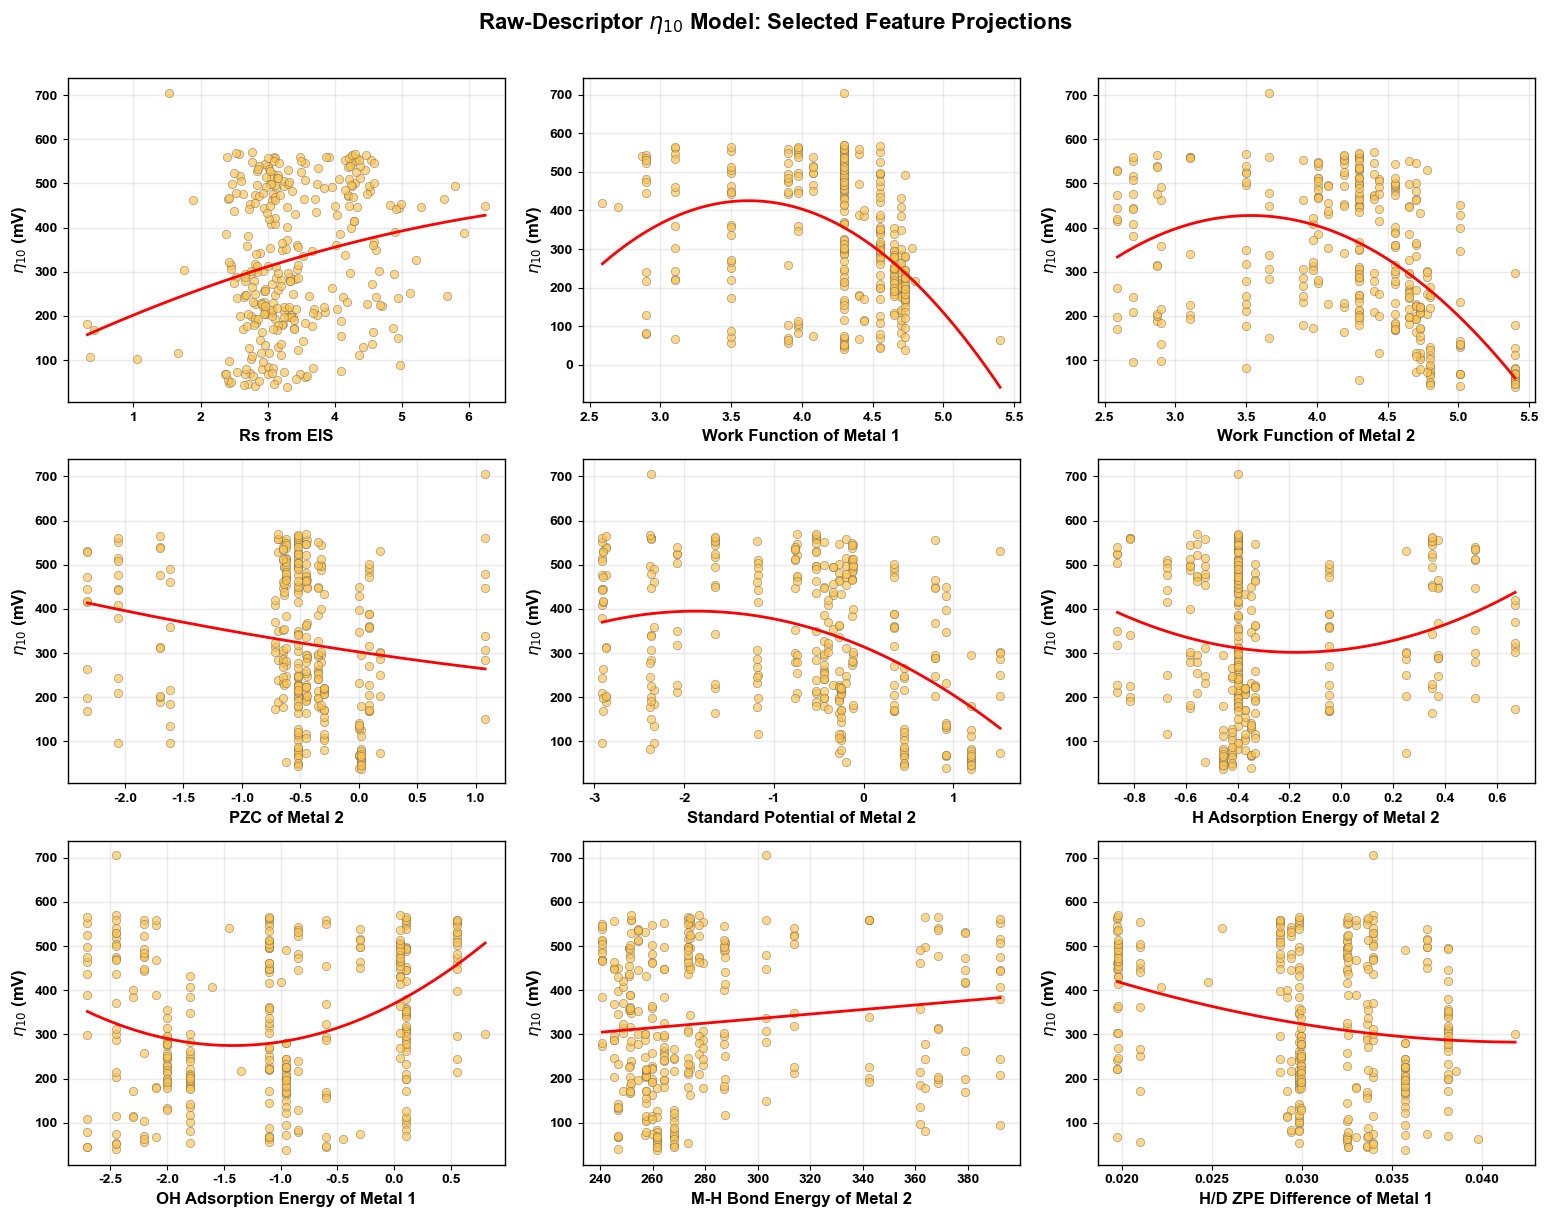

Plot outputs:
  C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_backward_elimination.png
  C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_feature_importance.png
  C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_raw_descriptor_prediction_residual.png
  C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_test_prediction_publication_style.png
  C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_vs_raw_workfunction_elements.png
  C:\Users\yibinjiang\Documents\GitHub\HD_separation\hd_separation_ml\outputs\03_eta10_activity_model_raw_descriptors\eta10_workfunction1_workfunction2_distribution.png
  C:\User

In [11]:

# Single-feature projections for the selected raw descriptors.
ncols = 3
nrows = int(np.ceil(len(selected_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.0 * nrows), squeeze=False)

for ax, feature in zip(axes.ravel(), selected_features):
    sub = work[[feature, "eta10_mV"]].copy()
    sub[feature] = pd.to_numeric(sub[feature], errors="coerce")
    sub = sub.dropna()
    ax.scatter(
        sub[feature],
        sub["eta10_mV"],
        s=36,
        alpha=0.68,
        color="#ffc44d",
        edgecolor="#666666",
        linewidth=0.45,
        zorder=3,
    )
    if sub[feature].nunique() > 2:
        xs = np.linspace(sub[feature].min(), sub[feature].max(), 200)
        coeff = np.polyfit(sub[feature], sub["eta10_mV"], deg=2)
        ax.plot(xs, np.polyval(coeff, xs), color="red", lw=2.0, zorder=4)
    ax.set_xlabel(display_feature_name(feature), fontsize=12, fontweight="bold", color="black")
    ax.set_ylabel(f"{ETA10} (mV)", fontsize=12, fontweight="bold", color="black")
    ax.grid(alpha=0.25, linewidth=1.0)
    format_axis_black_bold(ax, labelsize=10)

for ax in axes.ravel()[len(selected_features):]:
    ax.axis("off")

fig.suptitle(f"Raw-Descriptor {ETA10} Model: Selected Feature Projections", fontsize=16, fontweight="bold", color="black", y=1.01)
fig.tight_layout()
save_png_pdf(fig, "raw_selected_features_vs_eta10_scatter_grid")
plt.show()
plt.close(fig)

plot_outputs = sorted(OUTPUT_DIR.rglob("*.png"))
manifest_file = OUTPUT_DIR / "plot_outputs_manifest.csv"
pd.DataFrame({
    "plot_file": [str(path.relative_to(OUTPUT_DIR)) for path in plot_outputs],
    "full_path": [str(path.resolve()) for path in plot_outputs],
}).to_csv(manifest_file, index=False)

print("Plot outputs:")
for path in plot_outputs:
    print(f"  {path}")
print(f"Plot manifest saved to: {manifest_file}")


In [ ]:

# Combined ABCD summary figure for the eta10 activity model.
# A: test prediction; B: residuals; C: feature importance; D: work-function map.

import textwrap
from sklearn.metrics import r2_score, mean_squared_error


def wrap_label(text, width=28):
    return "\n".join(textwrap.wrap(text, width=width, break_long_words=False))


def format_axis_summary(ax, labelsize=10, linewidth=1.2):
    ax.tick_params(axis="both", labelsize=labelsize, colors="black", labelcolor="black", width=linewidth, length=4)
    for tick in ax.get_xticklabels() + ax.get_yticklabels():
        tick.set_fontname("Arial")
        tick.set_fontweight("bold")
        tick.set_color("black")
    ax.xaxis.label.set_fontname("Arial")
    ax.yaxis.label.set_fontname("Arial")
    ax.xaxis.label.set_fontweight("bold")
    ax.yaxis.label.set_fontweight("bold")
    ax.xaxis.label.set_color("black")
    ax.yaxis.label.set_color("black")
    ax.title.set_fontname("Arial")
    ax.title.set_fontweight("bold")
    ax.title.set_color("black")
    for spine in ax.spines.values():
        spine.set_linewidth(linewidth)
        spine.set_color("black")


def add_panel_label(ax, label):
    ax.text(
        -0.14,
        1.08,
        label,
        transform=ax.transAxes,
        fontsize=18,
        fontweight="bold",
        va="top",
        ha="left",
        color="black",
        family="Arial",
    )


plot_prediction_df = pd.read_csv(OUTPUT_DIR / "eta10_raw_descriptor_test_predictions.csv")
plot_importance_df = pd.read_csv(OUTPUT_DIR / "eta10_raw_descriptor_feature_importance.csv")
plot_work = pd.read_csv(OUTPUT_DIR / "eta10_ge20_model_dataset_raw_descriptors.csv")

plot_y_true = plot_prediction_df["true_eta10_mV"].to_numpy(dtype=float)
plot_y_pred = plot_prediction_df["predicted_eta10_mV"].to_numpy(dtype=float)
plot_residual = plot_y_pred - plot_y_true
plot_r2 = r2_score(plot_y_true, plot_y_pred)
plot_rmse = np.sqrt(mean_squared_error(plot_y_true, plot_y_pred))

plot_data = plot_work.copy()
for col in ["work_function_element1", "work_function_element2", "eta10_mV"]:
    plot_data[col] = pd.to_numeric(plot_data[col], errors="coerce")
plot_data = plot_data.dropna(subset=["work_function_element1", "work_function_element2", "eta10_mV"])

fig = plt.figure(figsize=(13.6, 9.4), dpi=300)
grid = fig.add_gridspec(
    2,
    2,
    left=0.08,
    right=0.965,
    bottom=0.075,
    top=0.94,
    wspace=0.30,
    hspace=0.35,
)

# A. Prediction
ax = fig.add_subplot(grid[0, 0])
lo = min(plot_y_true.min(), plot_y_pred.min())
hi = max(plot_y_true.max(), plot_y_pred.max())
pad = 0.07 * (hi - lo)
lo -= pad
hi += pad
ax.scatter(plot_y_true, plot_y_pred, s=54, color="#ffc44d", edgecolors="#4b5563", linewidths=0.65, alpha=0.86, zorder=3)
ax.plot([lo, hi], [lo, hi], color="red", linestyle="--", linewidth=2.2, label="Perfect prediction", zorder=2)
ax.set_xlim(lo, hi)
ax.set_ylim(lo, hi)
ax.set_aspect("equal", adjustable="box", anchor="W")
ax.set_xlabel(f"True {ETA10} (mV)", fontsize=12.5, fontweight="bold")
ax.set_ylabel(f"Predicted {ETA10} (mV)", fontsize=12.5, fontweight="bold")
ax.set_title(f"R? = {plot_r2:.4f}, RMSE = {plot_rmse:.1f} mV", fontsize=13, fontweight="bold", pad=8)
ax.grid(alpha=0.25, linewidth=0.9)
legend = ax.legend(loc="upper left", frameon=True, fontsize=9.5)
for text in legend.get_texts():
    text.set_fontweight("bold")
legend.get_frame().set_edgecolor("black")
format_axis_summary(ax, labelsize=10.5)
add_panel_label(ax, "A")

# B. Residuals
ax = fig.add_subplot(grid[0, 1])
ax.scatter(plot_y_true, plot_residual, s=54, color="#67a9cf", edgecolors="#4b5563", linewidths=0.65, alpha=0.86, zorder=3)
ax.axhline(0, color="red", linestyle="--", linewidth=2.2, zorder=2)
ax.set_xlabel(f"True {ETA10} (mV)", fontsize=12.5, fontweight="bold")
ax.set_ylabel("Residual: predicted - true (mV)", fontsize=12.5, fontweight="bold")
ax.set_title("Residual distribution", fontsize=13, fontweight="bold", pad=8)
ax.grid(alpha=0.25, linewidth=0.9)
format_axis_summary(ax, labelsize=10.5)
add_panel_label(ax, "B")

# C. Feature importance
ax = fig.add_subplot(grid[1, 0])
plot_imp = plot_importance_df.sort_values("native_importance").copy()
plot_imp["label"] = plot_imp["feature"].map(display_feature_name).map(lambda x: wrap_label(x, width=28))
bar_colors = plt.cm.Blues(np.linspace(0.42, 0.86, len(plot_imp)))
ax.barh(plot_imp["label"], plot_imp["native_importance"], color=bar_colors, edgecolor="black", linewidth=0.6)
ax.set_xlabel("Native tree importance", fontsize=12.5, fontweight="bold")
ax.set_title(f"{ETA10} activity model descriptors", fontsize=13, fontweight="bold", pad=8)
ax.grid(axis="x", alpha=0.25, linewidth=0.9)
format_axis_summary(ax, labelsize=8.8)
add_panel_label(ax, "C")

# D. Work-function descriptor map
ax = fig.add_subplot(grid[1, 1])
eta_vmax = np.nanpercentile(plot_data["eta10_mV"], 95)
sc = ax.scatter(
    plot_data["work_function_element1"],
    plot_data["work_function_element2"],
    c=plot_data["eta10_mV"],
    cmap="coolwarm",
    vmin=ETA10_MIN_MV,
    vmax=eta_vmax,
    s=46,
    alpha=0.86,
    edgecolor="black",
    linewidth=0.50,
)
cb = fig.colorbar(sc, ax=ax, pad=0.025, fraction=0.046)
cb.set_label(f"{ETA10} (mV)", fontsize=11.5, fontweight="bold", color="black")
cb.ax.tick_params(labelsize=9.5, colors="black")
for tick in cb.ax.get_yticklabels():
    tick.set_fontweight("bold")
cb.outline.set_edgecolor("black")
cb.outline.set_linewidth(1.1)
ax.set_xlabel("Work function of metal 1 (eV)", fontsize=12.5, fontweight="bold")
ax.set_ylabel("Work function of metal 2 (eV)", fontsize=12.5, fontweight="bold")
ax.set_title(f"{ETA10} distribution in raw work-function space", fontsize=13, fontweight="bold", pad=8)
ax.grid(alpha=0.22, linewidth=0.9)
format_axis_summary(ax, labelsize=10.5)
add_panel_label(ax, "D")

fig.savefig(OUTPUT_DIR / "eta10_activity_model_summary_ABCD.png", dpi=600, bbox_inches="tight", pad_inches=0.08)
fig.savefig(OUTPUT_DIR / "eta10_activity_model_summary_ABCD.pdf", bbox_inches="tight", pad_inches=0.08)
plt.show()
plt.close(fig)

print(f"Saved to: {OUTPUT_DIR / 'eta10_activity_model_summary_ABCD.png'}")
